In [24]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict, Literal, Annotated
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel, Field
import operator

In [ ]:
GEMINI_API_KEY = 
    model="gemini-3.6-flash",
    google_api_key=GEMINI_API_KEY
)

evaluator_llm = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=GEMINI_API_KEY
)

optimizer_llm = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=GEMINI_API_KEY
)

In [36]:
from pydantic import BaseModel, Field

class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the tweet.")

In [37]:
structured_evaluator_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [38]:
class TweetState(TypedDict):
    topic: str
    tweet: str
    evaluation: Literal["approved","need_improvement"]
    feedback: str
    max_iteration: int

    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [39]:
def generate_tweet(state:TweetState):
    # prompt
    messages=[
         SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    response=generator_llm.invoke(messages).content

    return {'tweet': response, 'tweet_history': [response]}


In [40]:
def evaluate_tweet(state: TweetState):

    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people retweet or share it?  
5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"  
- feedback: One paragraph explaining the strengths and weaknesses 
""")
]

    response = structured_evaluator_llm.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}

In [41]:
def optimize_tweet(state: TweetState):

    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
    ]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'tweet': response, 'iteration': iteration, 'tweet_history': [response]}

In [42]:
def route_evaluation(state: TweetState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

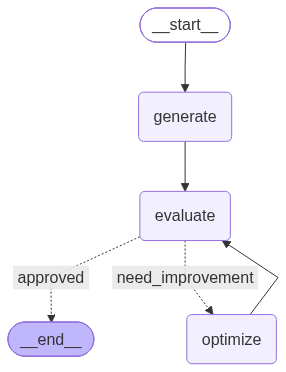

In [43]:
# graph designing 
graph=StateGraph(TweetState)

# create node
graph.add_node("generate",generate_tweet)
graph.add_node("evaluate",evaluate_tweet)
graph.add_node("optimize",optimize_tweet)

# connnect nodes acc to our design
graph.add_edge(START,'generate')
graph.add_edge('generate', 'evaluate')
graph.add_conditional_edges('evaluate', route_evaluation, {'approved':END, 'need_improvement':'optimize'})
graph.add_edge('optimize','evaluate')

workflow=graph.compile()
workflow


In [44]:
initial_state={
    "topic":"AIOPS",
    "iteration":1,
    "max_iteration":5
}

result=workflow.invoke(initial_state)

In [45]:
result

{'topic': 'AIOPS',
 'tweet': [{'type': 'text',
   'text': 'AIOps is incredible. It used to take our IT team three hours to accidentally crash the production server, but now an AI can do it in 0.002 seconds and email everyone a nice little pie chart about it.',
   'extras': {'signature': 'Ep0nCponARFNMg+zYU1Qlcn2cAcqzKvRVNCWsb4cqrrm3wczm5o9URGPBVVZVDR0sFRLeTkN/4PT8AM90p2dRZQHx38QG52hzkRG1DEEhLVtdwUh/pgFUVrgQkG5rY2XxjbTmMyPLKzvdeXU5LnlYBxl+vxnm6PWlnNwmaRccacxAWWvtZqNQKZDR34vtLNy2rylC5T+ARBCB9JGb//Y2H2fofavKNkSW75HeQJ7G4vXQCMBx0k5YdGgGCc4CAnW1Dy5eyl1bRodYcUciWyWauD1Rt3RRBInXlwdI6p0YDKxmlOaaXNihxzdA1pa2fOf91+mbo+Vd6J6Mn04xlIJk8Cuscez7eqyGDf/R0E19W5vbTnkJsb8NYMyYM3MrPEib9W7Dxp6CbaaI19DKNhKrgz5IDMmE4nJgnkO6UOiZJ9FbKULPF79N4uwMC7+TxOiarjb6DjpUJ30uZsItyeMC9cdkbKACKa2bXd/a94hTNrQC1dPvLvgmeGQENWOvjst39z2aqlOyzBE20MP592IwbhnAFGM7VlTZ8UVkZMn62V3+RCKx3D12l5R1dOWxZY0NvWDU7JehcCrcPhuTgtmF3xzuhQb/y04i3q97LhaKZb3WFJ6t7Ac1tZlQx+3rkNQQSyQVibXauREWv7k+W3TIKUrsraWnf9vZojMKupP4JA7Tj7hJYmVjoyGQVzNvgo7DmwtA5U